In [1]:
import pandas as pd
df=pd.read_csv("Demonstrativo.csv",sep=";",header=None, encoding='latin1')
df.columns=["ANO","CENA","CONTA","VALOR"]
df.head(25)

,ANO,CENA,CONTA,VALOR
0,Ano 1,Total Cen_00001,NaN,"0,025138815"
1,Ano 1,Total Cen_00001,BAL - Total do Ativo,"10.631.127.075,2579"
2,Ano 1,Total Cen_00001,BAL - Ativo Circulante,"1.795.720.872,17537"
3,Ano 1,Total Cen_00001,BAL - DisponÃ­vel,"1.205.264.965,51818"
4,Ano 1,Total Cen_00001,BAL - Contas a Receber - SWAP,"95.680.421,9232409"
5,Ano 1,Total Cen_00001,BAL - Contas a Receber - Partes Relacionadas,"584.661,46688296"
6,Ano 1,Total Cen_00001,BAL - Contas a Receber - Clientes,"453.870.957,151068"
7,Ano 1,Total Cen_00001,BAL - Estoques Diversos,"86.620,78872148"
8,Ano 1,Total Cen_00001,BAL - Outros CrÃ©ditos,"40.233.245,3272782"
9,Ano 1,Total Cen_00001,BAL - RealizÃ¡vel a Longo Prazo,"639.023.858,22772"


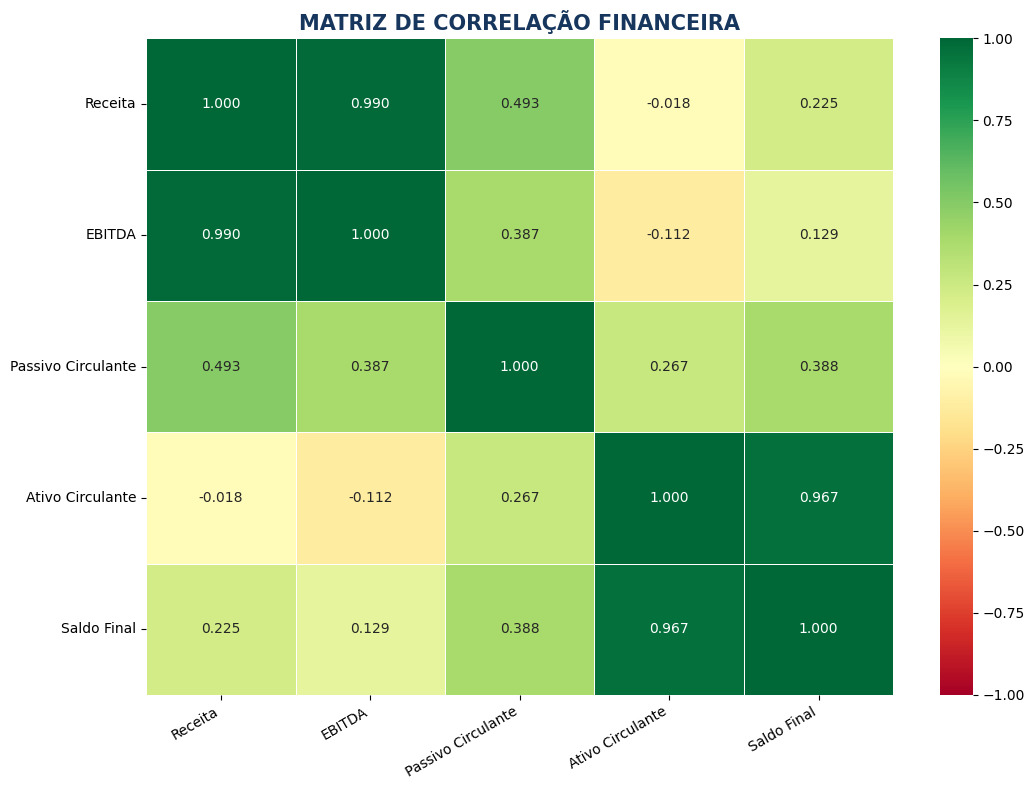

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import os

from IPython.display import display, HTML


# 1. CORES PADRÃO

COR_AZUL = "#4472C4"
COR_VERDE = "#70AD47"
COR_VERDE_CLARO = "#C6E0B4"
COR_FUNDO = "#F7FBF4"
COR_TOTAL = "#17365D"
COR_TOTAL_BORDA = "#0E243F"
COR_TEXTO = "#1F2937"
COR_BRANCO = "#FFFFFF"
COR_BORDA = "#D9E2F3"


# 2. CARREGAMENTO DOS DADOS

caminho = "/content/Demonstrativo.csv"

if os.path.exists(caminho):

    df = pd.read_csv(
        caminho,
        sep=";",
        encoding="latin1",
        header=None,
        names=["ANO", "CENARIO", "CONTA", "VALOR"],
        dtype=str
    )

elif "df" in globals():

    df = df.copy()

else:

    raise FileNotFoundError(
        "Arquivo Demonstrativo.csv não encontrado."
    )

df.columns = df.columns.astype(str).str.strip().str.upper()

colunas_necessarias = [
    "ANO", "CENARIO", "CONTA", "VALOR"
]

if not all(c in df.columns for c in colunas_necessarias):

    raise ValueError(
        f"Colunas encontradas: {df.columns.tolist()}"
    )


# 3. TRATAMENTO DOS VALORES

reg = df.copy()

reg["CONTA"] = reg["CONTA"].astype(str).str.strip()

reg["NOVOVALOR"] = pd.to_numeric(
    reg["VALOR"].astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)


# 4. CONVERSÃO PARA BILHÕES

reg["VALOR_BILHOES"] = (
    reg["NOVOVALOR"] / 1_000_000_000
)


# 5. TRATAMENTO DO ANO

reg["NUM_ANO"] = pd.to_numeric(
    reg["ANO"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)


# 6. NORMALIZAÇÃO DAS CONTAS

def normalizar(texto):

    texto = str(texto).lower().strip()

    return "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )


contas_disponiveis = (
    reg["CONTA"].dropna().drop_duplicates().tolist()
)


# 7. IDENTIFICAÇÃO DAS CONTAS

regras = {
    "Saldo Final": ("FLU", ["saldo final"]),
    "Receita": ("DRE", ["receita"]),
    "EBITDA": ("DRE", ["ebitda"]),
    "Passivo Circulante": ("BAL", ["passivo circulante"]),
    "Ativo Circulante": ("BAL", ["ativo circulante"])
}

selecionadas = {}

for indicador, (prefixo, termos) in regras.items():

    candidatas = [
        conta for conta in contas_disponiveis
        if normalizar(conta).startswith(prefixo.lower())
        and any(termo in normalizar(conta) for termo in termos)
        and "nao circulante" not in normalizar(conta)
    ]

    if indicador == "Receita":

        exatas = [
            conta for conta in candidatas
            if normalizar(conta) == "dre - receita"
        ]

        candidatas = exatas or [
            conta for conta in candidatas
            if "financeira" not in normalizar(conta)
        ]

    if len(candidatas) != 1:

        raise ValueError(
            f"Verifique a conta {indicador}: {candidatas}"
        )

    selecionadas[indicador] = candidatas[0]


# 8. PREPARAÇÃO DA BASE

reg_filtrado = reg[
    reg["CONTA"].isin(selecionadas.values())
].copy()

reg_filtrado["INDICADOR"] = reg_filtrado["CONTA"].map(
    {conta: indicador for indicador, conta in selecionadas.items()}
)

base_regressao = reg_filtrado.pivot_table(
    index=["NUM_ANO", "CENARIO"],
    columns="INDICADOR",
    values="VALOR_BILHOES",
    aggfunc="sum"
).reset_index()

base_regressao.columns.name = None

variaveis = [
    "Receita",
    "EBITDA",
    "Passivo Circulante",
    "Ativo Circulante"
]

base_regressao = base_regressao.dropna(
    subset=variaveis + ["Saldo Final"]
)


# 9. FORMATAÇÃO DOS VALORES

def formatar_numero(valor, casas=4):

    if pd.isna(valor):
        return "-"

    return (
        f"{valor:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )


# 10. FUNÇÃO PARA TABELAS HTML

def criar_tabela(titulo, colunas, linhas):

    cabecalho = "".join(
        f"""
        <th style="
            background-color:{COR_VERDE} !important;
            color:{COR_BRANCO} !important;
            padding:12px 16px;
            border:1px solid {COR_BORDA};
            text-align:center;
            font-weight:bold;
        ">{coluna}</th>
        """
        for coluna in colunas
    )

    corpo = ""

    for i, linha in enumerate(linhas):

        fundo = COR_FUNDO if i % 2 == 0 else "#EAF2E5"

        corpo += "<tr>"

        for valor in linha:

            corpo += f"""
            <td style="
                background-color:{fundo} !important;
                color:{COR_TEXTO} !important;
                padding:12px 16px;
                border:1px solid {COR_BORDA};
                text-align:center;
                font-weight:500;
            ">{valor}</td>
            """

        corpo += "</tr>"

    display(HTML(f"""
    <div style="
        overflow-x:auto;
        font-family:Arial,sans-serif;
        margin:20px 0;
    ">
        <table style="
            border-collapse:collapse;
            width:100%;
            min-width:700px;
            font-size:13px;
        ">
            <tr>
                <th colspan="{len(colunas)}" style="
                    background-color:{COR_TOTAL} !important;
                    color:{COR_BRANCO} !important;
                    padding:15px;
                    font-size:15px;
                ">{titulo}</th>
            </tr>
            <tr>{cabecalho}</tr>
            {corpo}
        </table>
    </div>
    """))


# 11. TABELA DAS VARIÁVEIS

criar_tabela(
    "VARIÁVEIS UTILIZADAS NA REGRESSÃO",
    ["INDICADOR", "CONTA ORIGINAL", "TIPO"],
    [
        [
            indicador,
            conta,
            "Dependente" if indicador == "Saldo Final"
            else "Independente"
        ]
        for indicador, conta in selecionadas.items()
    ]
)


# 12. MATRIZ DE CORRELAÇÃO

correlacao = base_regressao[
    variaveis + ["Saldo Final"]
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor=COR_BRANCO
)

plt.title(
    "MATRIZ DE CORRELAÇÃO FINANCEIRA",
    fontsize=15,
    fontweight="bold",
    color=COR_TOTAL
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

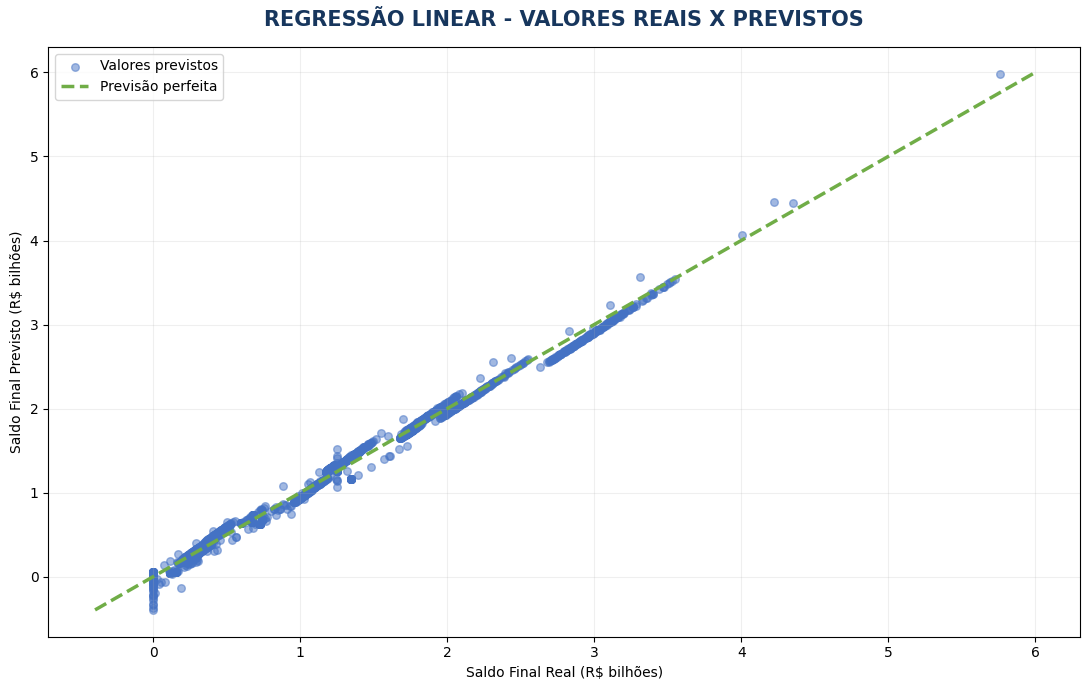

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# 1. DEFINIÇÃO DAS VARIÁVEIS

X = base_regressao[variaveis].copy()

y = base_regressao["Saldo Final"].copy()

grupos = base_regressao["CENARIO"]


# 2. DIVISÃO DOS DADOS

if grupos.nunique() < 2:

    raise ValueError(
        "São necessários pelo menos dois cenários."
    )

divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indice_treino, indice_teste = next(
    divisor.split(X, y, groups=grupos)
)

X_treino = X.iloc[indice_treino]
X_teste = X.iloc[indice_teste]

y_treino = y.iloc[indice_treino]
y_teste = y.iloc[indice_teste]


# 3. TREINAMENTO DA REGRESSÃO

modelo = LinearRegression()

modelo.fit(X_treino, y_treino)


# 4. PREVISÃO DOS RESULTADOS

y_previsto = modelo.predict(X_teste)


# 5. CÁLCULO DAS MÉTRICAS

r2_treino = r2_score(
    y_treino,
    modelo.predict(X_treino)
)

r2_teste = r2_score(
    y_teste,
    y_previsto
)

mae = mean_absolute_error(
    y_teste,
    y_previsto
)

rmse = np.sqrt(
    mean_squared_error(y_teste, y_previsto)
)


# 6. TABELA DAS MÉTRICAS

criar_tabela(
    "MÉTRICAS DA REGRESSÃO LINEAR MÚLTIPLA",
    ["MÉTRICA", "RESULTADO"],
    [
        ["R² Treinamento", formatar_numero(r2_treino)],
        ["R² Teste", formatar_numero(r2_teste)],
        ["MAE", f"R$ {formatar_numero(mae)} bilhões"],
        ["RMSE", f"R$ {formatar_numero(rmse)} bilhões"]
    ]
)


# 7. COEFICIENTES DA REGRESSÃO

coeficientes = pd.DataFrame({
    "Indicador": variaveis,
    "Coeficiente": modelo.coef_
})


# 8. TABELA DOS COEFICIENTES

criar_tabela(
    "COEFICIENTES DA REGRESSÃO",
    ["INDICADOR", "COEFICIENTE"],
    [
        [
            linha["Indicador"],
            formatar_numero(linha["Coeficiente"])
        ]
        for _, linha in coeficientes.iterrows()
    ]
)


# 9. INTERCEPTO DO MODELO

criar_tabela(
    "INTERCEPTO DA REGRESSÃO",
    ["PARÂMETRO", "VALOR"],
    [
        [
            "Intercepto",
            f"R$ {formatar_numero(modelo.intercept_)} bilhões"
        ]
    ]
)


# 10. GRÁFICO DOS VALORES REAIS E PREVISTOS

plt.figure(figsize=(11, 7))

plt.scatter(
    y_teste,
    y_previsto,
    color=COR_AZUL,
    alpha=0.5,
    s=30,
    label="Valores previstos"
)

limites = [
    min(y_teste.min(), y_previsto.min()),
    max(y_teste.max(), y_previsto.max())
]

plt.plot(
    limites,
    limites,
    color=COR_VERDE,
    linestyle="--",
    linewidth=2.5,
    label="Previsão perfeita"
)

plt.title(
    "REGRESSÃO LINEAR - VALORES REAIS X PREVISTOS",
    fontsize=15,
    fontweight="bold",
    color=COR_TOTAL,
    pad=15
)

plt.xlabel("Saldo Final Real (R$ bilhões)")
plt.ylabel("Saldo Final Previsto (R$ bilhões)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

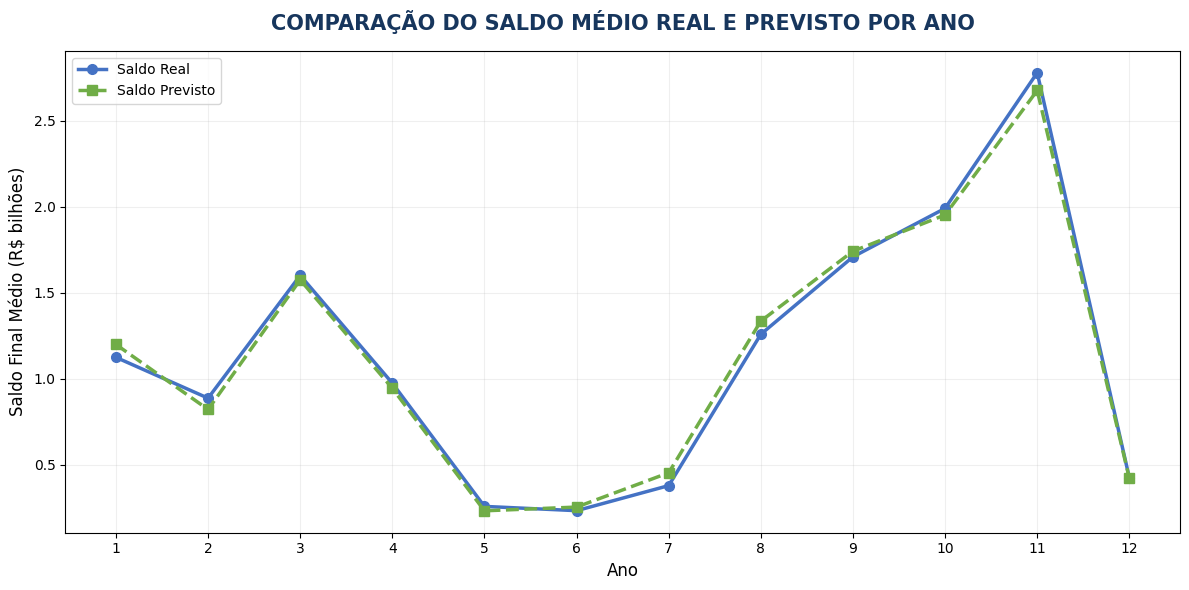

Análise de regressão concluída.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 1. PREPARAÇÃO DOS RESULTADOS

resultados = base_regressao.iloc[indice_teste][
    ["NUM_ANO", "CENARIO"]
].copy()

resultados["SALDO_REAL"] = y_teste.values

resultados["SALDO_PREVISTO"] = y_previsto

resultados["DIFERENCA"] = (
    resultados["SALDO_REAL"] -
    resultados["SALDO_PREVISTO"]
)


# 2. AGRUPAMENTO DOS RESULTADOS POR ANO

comparacao_ano = (
    resultados.groupby(
        "NUM_ANO",
        as_index=False
    )[
        ["SALDO_REAL", "SALDO_PREVISTO"]
    ].mean()
)

comparacao_ano = comparacao_ano.sort_values(
    "NUM_ANO"
)


# 3. GRÁFICO DO SALDO REAL E PREVISTO

plt.figure(figsize=(12, 6))

plt.plot(
    comparacao_ano["NUM_ANO"],
    comparacao_ano["SALDO_REAL"],
    marker="o",
    markersize=7,
    linewidth=2.5,
    color=COR_AZUL,
    label="Saldo Real"
)

plt.plot(
    comparacao_ano["NUM_ANO"],
    comparacao_ano["SALDO_PREVISTO"],
    marker="s",
    markersize=7,
    linewidth=2.5,
    linestyle="--",
    color=COR_VERDE,
    label="Saldo Previsto"
)

plt.title(
    "COMPARAÇÃO DO SALDO MÉDIO REAL E PREVISTO POR ANO",
    fontsize=15,
    fontweight="bold",
    color=COR_TOTAL,
    pad=15
)

plt.xlabel("Ano", fontsize=12)

plt.ylabel(
    "Saldo Final Médio (R$ bilhões)",
    fontsize=12
)

plt.xticks(comparacao_ano["NUM_ANO"])

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# 4. TABELA DOS RESULTADOS POR ANO

linhas_ano = []

for _, linha in comparacao_ano.iterrows():

    linhas_ano.append([
        int(linha["NUM_ANO"]),
        f'R$ {formatar_numero(linha["SALDO_REAL"], 3)}',
        f'R$ {formatar_numero(linha["SALDO_PREVISTO"], 3)}'
    ])

criar_tabela(
    "COMPARAÇÃO FINANCEIRA POR ANO - R$ BILHÕES",
    ["ANO", "SALDO REAL", "SALDO PREVISTO"],
    linhas_ano
)


# 5. RESUMO FINAL DA REGRESSÃO

resumo = [
    ["Modelo", "Regressão Linear Múltipla"],
    ["Variável dependente", "Saldo Final de Caixa"],
    ["Variáveis independentes", ", ".join(variaveis)],
    ["Observações", len(base_regressao)],
    ["Cenários", base_regressao["CENARIO"].nunique()],
    ["R² Treinamento", formatar_numero(r2_treino)],
    ["R² Teste", formatar_numero(r2_teste)],
    ["MAE", f"R$ {formatar_numero(mae)} bilhões"],
    ["RMSE", f"R$ {formatar_numero(rmse)} bilhões"]
]

criar_tabela(
    "RESUMO DA ANÁLISE DE REGRESSÃO FINANCEIRA",
    ["INFORMAÇÃO", "RESULTADO"],
    resumo
)

print("Análise de regressão concluída.")